<a href="https://colab.research.google.com/github/bubs-art/ML/blob/main/swin_pneumonia_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pneumonia Detection with Swin Transformer
Model: Swin-T (Swin Transformer), fine-tuned to classify chest X-rays as NORMAL or PNEUMONIA.

### 1. Dataset setup

In [ ]:
!pip install -q kaggle grad-cam

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, subprocess, getpass

DATA_DIR = "/content/data"
if not os.path.isdir(f"{DATA_DIR}/chest_xray"):
    os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
    token = getpass.getpass("Paste your NEW Kaggle token: ").strip()
    tok_path = os.path.expanduser("~/.kaggle/access_token")
    with open(tok_path, "w") as f: f.write(token)
    os.chmod(tok_path, 0o600)
    os.environ["KAGGLE_API_TOKEN"] = token
    subprocess.run(["kaggle", "datasets", "download", "-d", "paultimothymooney/chest-xray-pneumonia",
                    "-p", DATA_DIR, "--unzip"], check=True)
else:
    print("Dataset already downloaded.")

ROOT = "/content/data/chest_xray/chest_xray"
if not os.path.isdir(f"{ROOT}/train/NORMAL"):
    ROOT = "/content/data/chest_xray"
assert os.path.isdir(f"{ROOT}/train/NORMAL"), "Dataset folders not found."
print("ROOT:", ROOT)

Paste your NEW Kaggle token: ··········
ROOT: /content/data/chest_xray/chest_xray


In [ ]:
import re, time, random
import numpy as np, pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms as T
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, precision_score, recall_score
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 2. Data loading
Build `data.csv` (image path, label, split) from the folders, then read it with `read_csv`.

In [ ]:
rows = []
for split in ["train", "val", "test"]:
    for label, cls in enumerate(["NORMAL", "PNEUMONIA"]):          # NORMAL=0, PNEUMONIA=1
        folder = f"{ROOT}/{split}/{cls}"
        for f in os.listdir(folder):
            if f.lower().endswith((".jpeg", ".jpg", ".png")):
                rows.append({"path": f"{folder}/{f}", "label": label, "class": cls, "split": split})
pd.DataFrame(rows).to_csv("data.csv", index=False)

df = pd.read_csv("data.csv")
print(df.shape)
df.head()

(5856, 4)


,path,label,class,split
0,/content/data/chest_xray/chest_xray/train/NORM...,0,NORMAL,train
1,/content/data/chest_xray/chest_xray/train/NORM...,0,NORMAL,train
2,/content/data/chest_xray/chest_xray/train/NORM...,0,NORMAL,train
3,/content/data/chest_xray/chest_xray/train/NORM...,0,NORMAL,train
4,/content/data/chest_xray/chest_xray/train/NORM...,0,NORMAL,train


## 3. EDA
Class balance per split and image size statistics.

class  NORMAL  PNEUMONIA
split                   
test      234        390
train    1341       3875
val         8          8

pneumonia : normal in train = 2.89


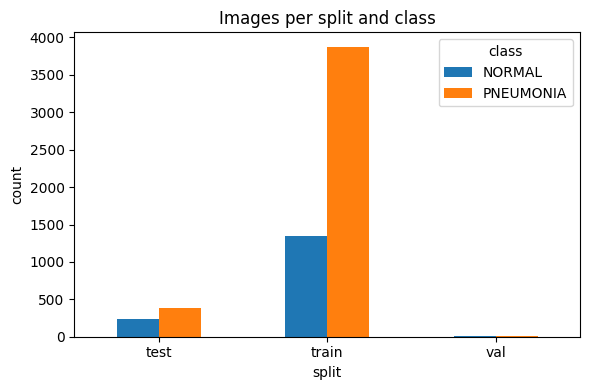

            w       h
count  5856.0  5856.0
mean   1328.0   971.0
std     364.0   383.0
min     384.0   127.0
25%    1056.0   688.0
50%    1281.0   888.0
75%    1560.0  1187.0
max    2916.0  2713.0


In [ ]:
counts = df.groupby(["split", "class"]).size().unstack()
print(counts)
print("\npneumonia : normal in train =", round(counts.loc["train", "PNEUMONIA"] / counts.loc["train", "NORMAL"], 2))

counts.plot(kind="bar", figsize=(6, 4), rot=0, title="Images per split and class")
plt.ylabel("count"); plt.tight_layout(); plt.show()

sizes = [Image.open(p).size for p in df.path]          # reads headers only, fast
df["w"], df["h"] = [s[0] for s in sizes], [s[1] for s in sizes]
print(df[["w", "h"]].describe().round(0))

## 4. Image visualization
Sample X-rays and pixel-intensity distribution per class.

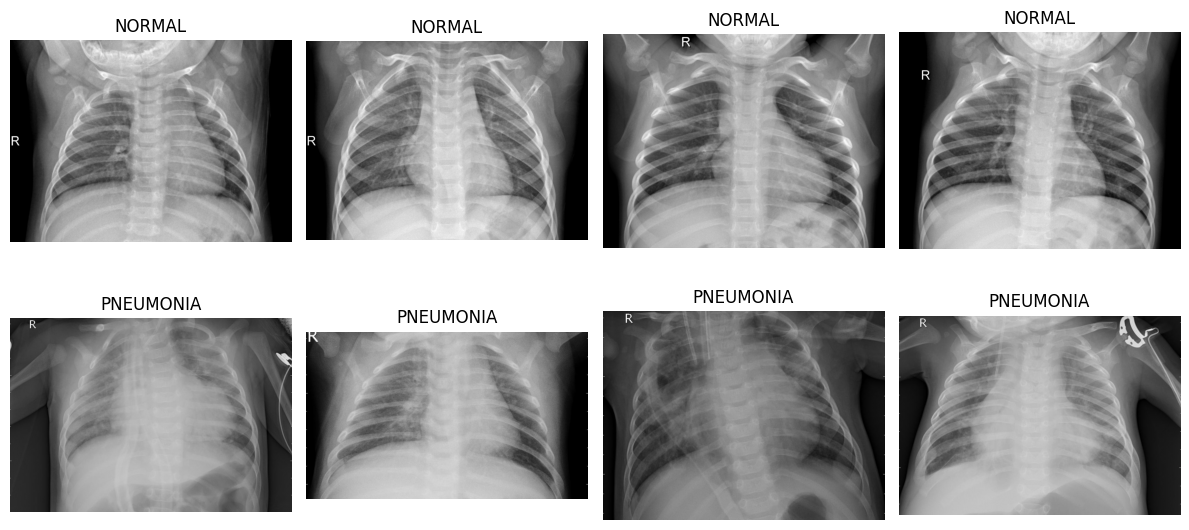

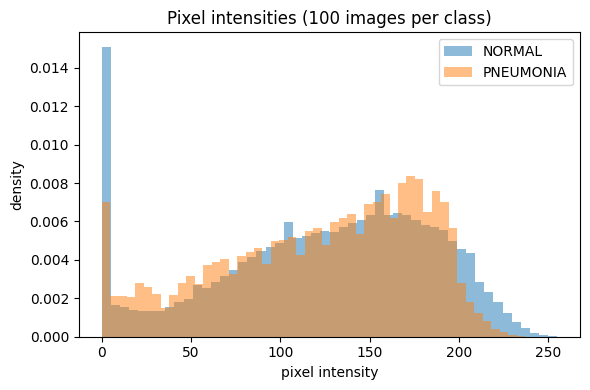

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for r, cls in enumerate(["NORMAL", "PNEUMONIA"]):
    paths = df[(df["split"] == "train") & (df["class"] == cls)].path.head(4)
    for c, p in enumerate(paths):
        axes[r, c].imshow(Image.open(p).convert("L"), cmap="gray")
        axes[r, c].set_title(cls); axes[r, c].axis("off")
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
for cls in ["NORMAL", "PNEUMONIA"]:
    sample = df[(df["split"] == "train") & (df["class"] == cls)].path.sample(100, random_state=SEED)
    px = np.concatenate([np.asarray(Image.open(p).convert("L").resize((64, 64))).ravel() for p in sample])
    plt.hist(px, bins=50, alpha=0.5, density=True, label=cls)
plt.xlabel("pixel intensity"); plt.ylabel("density"); plt.legend(); plt.title("Pixel intensities (100 images per class)")
plt.tight_layout(); plt.show()

## 5. Bad-image removal
Drop unreadable, tiny or blank (near-constant) images.

In [ ]:
bad = []
for p in df.path:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size
            g = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32)
        if min(w, h) < 64 or g.std() < 1.0:
            bad.append(p)
    except Exception:
        bad.append(p)

print("images removed:", len(bad))
df = df[~df.path.isin(bad)].reset_index(drop=True)
print("images kept:", len(df))

images removed: 0
images kept: 5856


## 6. Data selection
The official `val` folder has only 16 images, so it is merged into `train` to form a development pool. `test` is held out and used once at the end.

In [ ]:
trainval = df[df["split"].isin(["train", "val"])].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)
print("development pool:", len(trainval), "| held-out test:", len(test_df))

development pool: 5232 | held-out test: 624


## 7. Normalization
Resize to 224x224 and normalize with ImageNet statistics, which is what the pretrained Swin weights expect.

In [ ]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
eval_tf = T.Compose([T.Resize((224, 224)), T.ToTensor(), T.Normalize(mean, std)])

x = eval_tf(Image.open(trainval.path[0]).convert("RGB"))
print("tensor shape:", tuple(x.shape))
print("per-channel mean after normalization:", x.mean(dim=(1, 2)).numpy().round(2))
print("per-channel std  after normalization:", x.std(dim=(1, 2)).numpy().round(2))

tensor shape: (3, 224, 224)
per-channel mean after normalization: [-0.09  0.03  0.26]
per-channel std  after normalization: [1.13 1.15 1.15]


## 8. Patch and window creation
Swin cuts the image into 4x4-pixel patches (tokens) and runs attention inside 7x7-token windows.

stage 1: 56x56 = 3136 tokens, window 7x7 tokens -> 64 windows
  stage 1: 56x56 tokens, 64 window(s)
  stage 2: 28x28 tokens, 16 window(s)
  stage 3: 14x14 tokens, 4 window(s)
  stage 4: 7x7 tokens, 1 window(s)


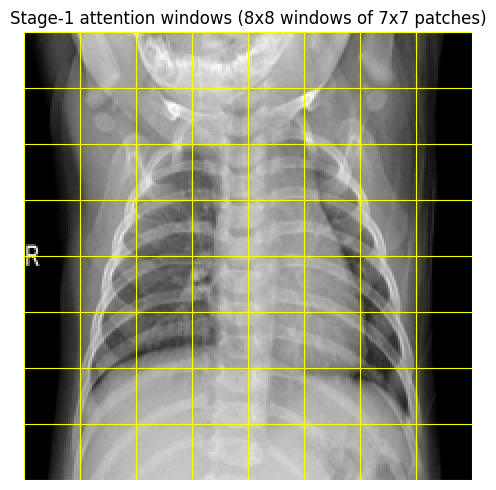

In [ ]:
img_size, patch, win = 224, 4, 7
tokens = img_size // patch                      # 56 tokens per side
print(f"stage 1: {tokens}x{tokens} = {tokens**2} tokens, window {win}x{win} tokens -> {(tokens // win)**2} windows")
for s, res in enumerate([56, 28, 14, 7], start=1):
    print(f"  stage {s}: {res}x{res} tokens, {max(res // win, 1)**2} window(s)")

img = Image.open(trainval.path[0]).convert("L").resize((img_size, img_size))
step = patch * win                              # 28 px per window
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(img, cmap="gray")
for k in range(0, img_size + 1, step):
    ax.axhline(k - 0.5, color="yellow", lw=0.8); ax.axvline(k - 0.5, color="yellow", lw=0.8)
ax.set_title("Stage-1 attention windows (8x8 windows of 7x7 patches)"); ax.axis("off")
plt.tight_layout(); plt.show()

## 9. Patient-level train/validation split
One patient has several X-rays, so a random image split would put the same patient in both sets and inflate the validation score. Patient IDs are parsed from the file names, and whole patients go to either train or validation.

In [ ]:
def patient_id(path):
    name = os.path.basename(path)
    m = re.search(r"(person\d+)", name)       # pneumonia: person123_bacteria_456.jpeg
    if m: return m.group(1)
    m = re.search(r"(IM-\d+)", name)          # normal: IM-0115-0001.jpeg / NORMAL2-IM-1427-0001.jpeg
    if m: return m.group(1)
    return os.path.splitext(name)[0]          # fallback: treat each image as its own patient

trainval["patient"] = trainval.path.apply(patient_id)
print("patients:", trainval.patient.nunique(), "| images:", len(trainval))

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)   # 1 of 7 folds, about 14%
tr_idx, va_idx = next(sgkf.split(trainval, trainval.label, groups=trainval.patient))
train_df, val_df = trainval.iloc[tr_idx].reset_index(drop=True), trainval.iloc[va_idx].reset_index(drop=True)

overlap = set(train_df.patient) & set(val_df.patient)
assert len(overlap) == 0, "patient leak between train and validation"
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)} | patient overlap: {len(overlap)}")
print("val pneumonia share:", round(val_df.label.mean(), 2), "| train pneumonia share:", round(train_df.label.mean(), 2))

patients: 2650 | images: 5232
train 4489 | val 743 | test 624 | patient overlap: 0
val pneumonia share: 0.76 | train pneumonia share: 0.74


## 10. Class-imbalance preparation
The training set has about 3 pneumonia images for every normal one, so the loss gives the minority class more weight. Augmentation is applied to training images only.

In [ ]:
n_normal, n_pneumonia = int((train_df.label == 0).sum()), int((train_df.label == 1).sum())
class_w = torch.tensor([n_pneumonia / n_normal, 1.0], device=device)
print("normal:", n_normal, "| pneumonia:", n_pneumonia, "| class weights:", class_w.cpu().numpy().round(2))

train_tf = T.Compose([T.Resize((224, 224)), T.RandomRotation(10),
                      T.RandomResizedCrop(224, scale=(0.9, 1.0)), T.ColorJitter(brightness=0.1),
                      T.ToTensor(), T.Normalize(mean, std)])

class XrayDataset(Dataset):
    def __init__(self, frame, tf): self.frame, self.tf = frame, tf
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        return self.tf(Image.open(row["path"]).convert("RGB")), int(row["label"])

BS = 32   # use 16 if you get an out-of-memory error
train_dl = DataLoader(XrayDataset(train_df, train_tf), batch_size=BS, shuffle=True, num_workers=2)
val_dl   = DataLoader(XrayDataset(val_df, eval_tf), batch_size=64, num_workers=2)
test_dl  = DataLoader(XrayDataset(test_df, eval_tf), batch_size=64, num_workers=2)

normal: 1170 | pneumonia: 3319 | class weights: [2.84 1.  ]


## 11. Swin Transformer architecture
Swin-T pretrained on ImageNet, with the classification head replaced by a 2-class layer.

In [ ]:
swin = models.swin_t(weights=models.Swin_T_Weights.DEFAULT)
swin.head = nn.Linear(swin.head.in_features, 2)      # 0 = NORMAL, 1 = PNEUMONIA
swin = swin.to(device)

print("parameters:", round(sum(p.numel() for p in swin.parameters()) / 1e6, 1), "M")
print("patch embedding :", swin.features[0])
print("stages (blocks per stage):", [len(swin.features[i]) for i in (1, 3, 5, 7)])
print("head            :", swin.head)

Downloading: "https://download.pytorch.org/models/swin_t-704ceda3.pth" to /root/.cache/torch/hub/checkpoints/swin_t-704ceda3.pth


100%|██████████| 108M/108M [00:00<00:00, 160MB/s] 


parameters: 27.5 M
patch embedding : Sequential(
  (0): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
  (1): Permute()
  (2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
)
stages (blocks per stage): [2, 2, 6, 2]
head            : Linear(in_features=768, out_features=2, bias=True)


## 12. Model training
AdamW + cosine schedule, mixed precision. The checkpoint with the best validation ROC-AUC is kept.

epoch 1/10  loss 0.2004  val AUC 0.9969
epoch 2/10  loss 0.0943  val AUC 0.9968
epoch 3/10  loss 0.0803  val AUC 0.9967
epoch 4/10  loss 0.0561  val AUC 0.9987
epoch 5/10  loss 0.0496  val AUC 0.9980
epoch 6/10  loss 0.0431  val AUC 0.9986
epoch 7/10  loss 0.0320  val AUC 0.9989
epoch 8/10  loss 0.0314  val AUC 0.9990
epoch 9/10  loss 0.0300  val AUC 0.9991
epoch 10/10  loss 0.0236  val AUC 0.9991
best val AUC 0.9991 | train time 16.9 min


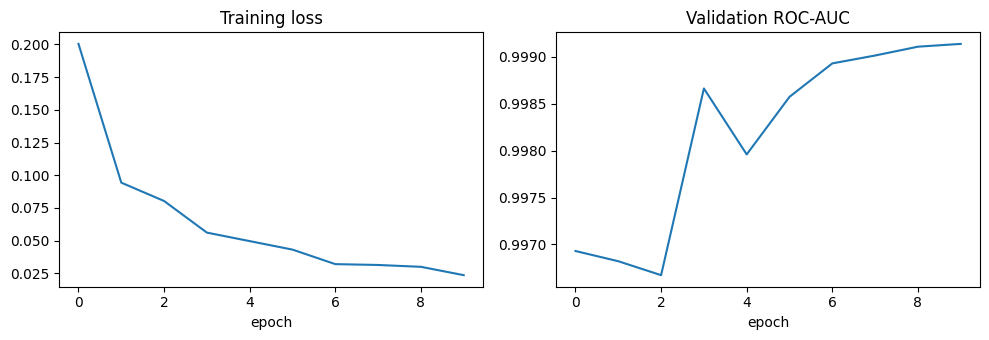

In [ ]:
EPOCHS = 10
criterion = nn.CrossEntropyLoss(weight=class_w)
optimizer = torch.optim.AdamW(swin.parameters(), lr=3e-5, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
scaler = torch.amp.GradScaler("cuda", enabled=device.type == "cuda")

def get_probs(model, dl):
    model.eval(); probs, ys = [], []
    with torch.no_grad(), torch.autocast("cuda", enabled=device.type == "cuda"):
        for x, y in dl:
            probs += torch.softmax(model(x.to(device)).float(), 1)[:, 1].cpu().tolist()
            ys += y.tolist()
    return np.array(probs), np.array(ys)

history, best_auc, t0 = [], 0.0, time.time()
for epoch in range(EPOCHS):
    swin.train(); total = 0.0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast("cuda", enabled=device.type == "cuda"):
            loss = criterion(swin(x), y)
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        total += loss.item() * len(y)
    scheduler.step()
    p, y_val = get_probs(swin, val_dl)
    auc = roc_auc_score(y_val, p)
    history.append((total / len(train_df), auc))
    print(f"epoch {epoch+1}/{EPOCHS}  loss {total/len(train_df):.4f}  val AUC {auc:.4f}")
    if auc > best_auc:
        best_auc = auc; torch.save(swin.state_dict(), "swin_t_best.pt")

swin.load_state_dict(torch.load("swin_t_best.pt"))
train_minutes = (time.time() - t0) / 60
print(f"best val AUC {best_auc:.4f} | train time {train_minutes:.1f} min")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot([h[0] for h in history]); ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot([h[1] for h in history]); ax[1].set_title("Validation ROC-AUC"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

## 13. Prediction-score calculation
Each image gets a pneumonia probability; a good model puts the two classes at opposite ends.

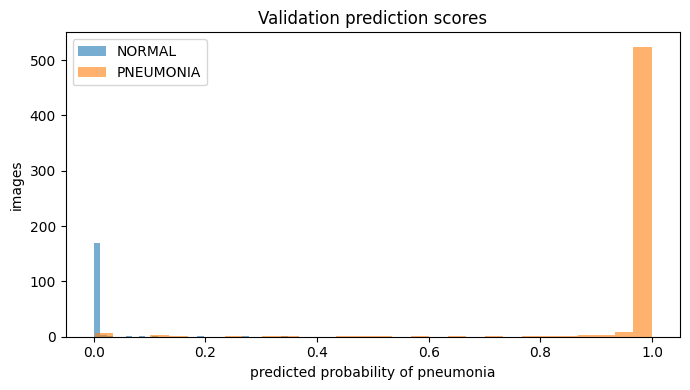

validation ROC-AUC: 0.9991


In [ ]:
p_val, y_val = get_probs(swin, val_dl)

plt.figure(figsize=(7, 4))
plt.hist(p_val[y_val == 0], bins=30, alpha=0.6, label="NORMAL")
plt.hist(p_val[y_val == 1], bins=30, alpha=0.6, label="PNEUMONIA")
plt.xlabel("predicted probability of pneumonia"); plt.ylabel("images"); plt.legend()
plt.title("Validation prediction scores")
plt.tight_layout(); plt.show()
print("validation ROC-AUC:", round(roc_auc_score(y_val, p_val), 4))

## 14. Decision threshold
Missing pneumonia is the costly mistake, so the threshold is the highest one on validation that still reaches 95% recall.

threshold: 0.363
validation recall: 0.977 | precision: 1.0


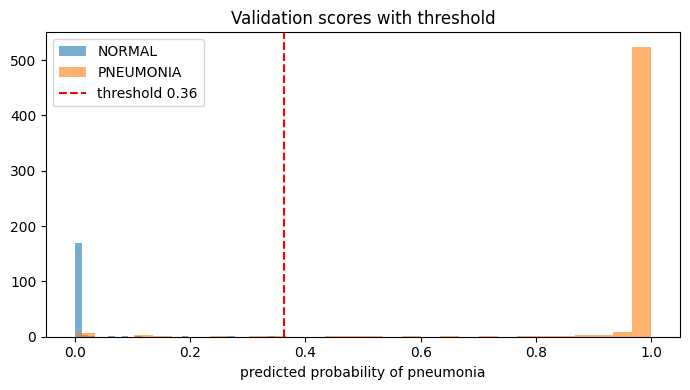

In [ ]:
fpr, tpr, thr = roc_curve(y_val, p_val)
threshold = float(thr[np.argmax(tpr >= 0.95)])
val_pred = (p_val >= threshold).astype(int)
print("threshold:", round(threshold, 4))
print("validation recall:", round(recall_score(y_val, val_pred), 4),
      "| precision:", round(precision_score(y_val, val_pred), 4))

plt.figure(figsize=(7, 4))
plt.hist(p_val[y_val == 0], bins=30, alpha=0.6, label="NORMAL")
plt.hist(p_val[y_val == 1], bins=30, alpha=0.6, label="PNEUMONIA")
plt.axvline(threshold, color="red", ls="--", label=f"threshold {threshold:.2f}")
plt.xlabel("predicted probability of pneumonia"); plt.legend(); plt.title("Validation scores with threshold")
plt.tight_layout(); plt.show()

## 15. Final evaluation on the held-out test set
Run once, with the threshold fixed in step 14.

In [ ]:
p_test, y_test = get_probs(swin, test_dl)
pred_test = (p_test >= threshold).astype(int)
cm_swin = confusion_matrix(y_test, pred_test)

results = pd.DataFrame([{
    "model": "Swin-T fine-tuned", "threshold": round(threshold, 4),
    "recall": round(recall_score(y_test, pred_test), 4),
    "precision": round(precision_score(y_test, pred_test), 4),
    "roc_auc": round(roc_auc_score(y_test, p_test), 4),
    "train_min": round(train_minutes, 1)}])
results.to_csv("results.csv", index=False)
print(results.to_string(index=False))
print("confusion matrix [[TN FP],[FN TP]]:\n", cm_swin)

            model  threshold  recall  precision  roc_auc  train_min
Swin-T fine-tuned      0.363  0.9949     0.8509   0.9811       16.9
confusion matrix [[TN FP],[FN TP]]:
 [[166  68]
 [  2 388]]


## 16. Confusion matrix

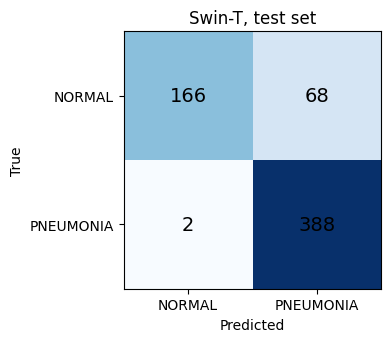

In [ ]:
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm_swin, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm_swin[i, j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1]); ax.set_xticklabels(["NORMAL", "PNEUMONIA"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["NORMAL", "PNEUMONIA"])
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Swin-T, test set")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=150); plt.show()

## 17. Grad-CAM heatmaps
Check that the heatmaps sit on the lungs, not on text markers or image borders.

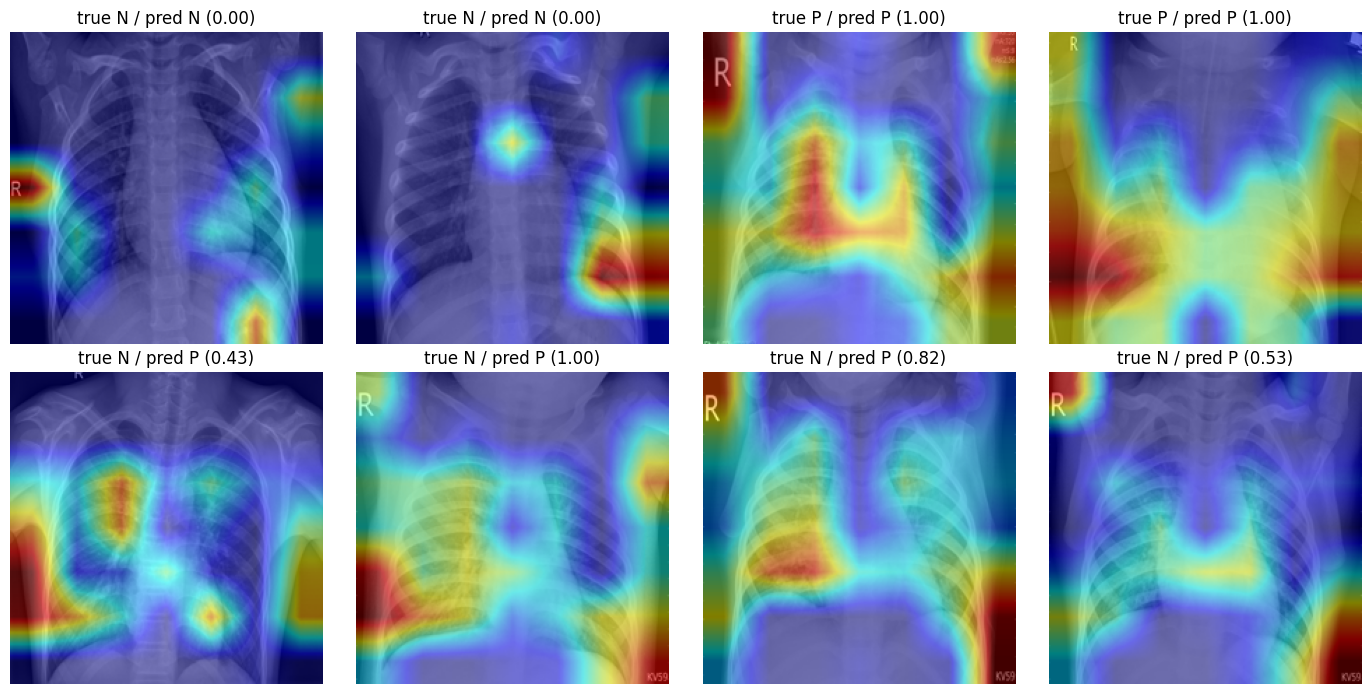

In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

swin.eval()
target_layers = [swin.features[-1][-1].norm1]
cam = GradCAM(model=swin, target_layers=target_layers,
              reshape_transform=lambda t: t.permute(0, 3, 1, 2))   # (B,H,W,C) -> (B,C,H,W)

correct = np.where(pred_test == y_test)[0]
wrong = np.where(pred_test != y_test)[0]
rng = np.random.RandomState(SEED)
chosen = list(rng.choice(correct, 4, replace=False)) + list(rng.choice(wrong, min(4, len(wrong)), replace=False))

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.ravel(), chosen):
    path = test_df.iloc[idx]["path"]
    x = eval_tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    rgb = np.asarray(Image.open(path).convert("RGB").resize((224, 224))) / 255.0
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
    ax.imshow(show_cam_on_image(rgb.astype(np.float32), heat, use_rgb=True))
    ax.set_title(f"true {['N','P'][y_test[idx]]} / pred {['N','P'][pred_test[idx]]} ({p_test[idx]:.2f})")
    ax.axis("off")
plt.tight_layout(); plt.savefig("gradcam_swin.png", dpi=150); plt.show()